# DATA 255 - Lab 3: Super Resolution (Ultra Fast NPU)
### Spring 2026 | San Jose State University
---
**Goal:** PSNR > 24 dB + Minimize NPU Latency

**Architecture:** SwiftSRNet — Downsample/Upsample with additive skips

**Key:** Process at lower resolution = ultra fast NPU inference!

**Drive Folder:** Lab3

## Cell 1: Install Packages

In [1]:
!pip install onnx onnxruntime onnxscript -q
print('All packages installed! ')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.6/17.6 MB 128.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.0/18.0 MB 131.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 714.8/714.8 kB 65.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 166.8/166.8 kB 13.4 MB/s eta 0:00:00
All packages installed! 


## Cell 2: Mount Google Drive

In [2]:
from google.colab import drive
drive.mount('/content/drive')
print('Drive mounted!')

Mounted at /content/drive
Drive mounted!


## Cell 3: Check GPU + Set Seeds

In [3]:
import torch
import numpy as np
import random
import os

SEED = 42
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
np.random.seed(SEED)
random.seed(SEED)
torch.backends.cudnn.benchmark = True

print(f'PyTorch version : {torch.__version__}')
print(f'GPU available   : {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'GPU name        : {torch.cuda.get_device_name(0)}')
    print(f'GPU memory      : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device    : {DEVICE}')

PyTorch version : 2.10.0+cu128
GPU available   : True
GPU name        : NVIDIA A100-SXM4-40GB
GPU memory      : 42.4 GB
Using device    : cuda


## Cell 4: Unzip ALL 12 Dataset Files

In [4]:
import zipfile
import os
import time

DRIVE_PATH = '/content/drive/MyDrive/Lab3'
DATA_ROOT  = '/content/data'
os.makedirs(DATA_ROOT, exist_ok=True)

zip_files = {
    'L3_LR_train' : f'{DRIVE_PATH}/L3_LR_train.zip',
    'L3_LR_train1': f'{DRIVE_PATH}/L3_LR_train1.zip',
    'L3_LR_train2': f'{DRIVE_PATH}/L3_LR_train2.zip',
    'L3_LR_train3': f'{DRIVE_PATH}/L3_LR_train3.zip',
    'L3_LR_train4': f'{DRIVE_PATH}/L3_LR_train4.zip',
    'L3_HR_train' : f'{DRIVE_PATH}/L3_HR_train.zip',
    'L3_HR_train1': f'{DRIVE_PATH}/L3_HR_train1.zip',
    'L3_HR_train2': f'{DRIVE_PATH}/L3_HR_train2.zip',
    'L3_HR_train3': f'{DRIVE_PATH}/L3_HR_train3.zip',
    'L3_HR_train4': f'{DRIVE_PATH}/L3_HR_train4.zip',
    'L3_LR_valid' : f'{DRIVE_PATH}/L3_LR_valid.zip',
    'L3_HR_valid' : f'{DRIVE_PATH}/L3_HR_valid.zip',
}

for name, zip_path in zip_files.items():
    extract_path = os.path.join(DATA_ROOT, name)
    if os.path.exists(extract_path):
        print(f'Already extracted: {name} ')
        continue
    for attempt in range(3):
        try:
            print(f'Extracting {name}...')
            with zipfile.ZipFile(zip_path, 'r') as zf:
                zf.extractall(extract_path)
            print(f'  Done ')
            break
        except OSError as e:
            print(f'  Error: {e} - Remounting...')
            time.sleep(3)
            from google.colab import drive
            drive.mount('/content/drive', force_remount=True)
            time.sleep(5)

print('\nAll zips extracted!')

Extracting L3_LR_train...
  Done 
Extracting L3_LR_train1...
  Done 
Extracting L3_LR_train2...
  Done 
Extracting L3_LR_train3...
  Done 
Extracting L3_LR_train4...
  Done 
Extracting L3_HR_train...
  Done 
Extracting L3_HR_train1...
  Done 
Extracting L3_HR_train2...
  Done 
Extracting L3_HR_train3...
  Done 
Extracting L3_HR_train4...
  Done 
Extracting L3_LR_valid...
  Done 
Extracting L3_HR_valid...
  Done 

All zips extracted!


## Cell 5: Verify Dataset

In [5]:
from glob import glob

def get_images(folder):
    return sorted([
        f for f in glob(os.path.join(folder, '**', '*'), recursive=True)
        if f.lower().endswith(('.png', '.jpg', '.jpeg'))
    ])

lr_train_dirs = [
    f'{DATA_ROOT}/L3_LR_train',  f'{DATA_ROOT}/L3_LR_train1',
    f'{DATA_ROOT}/L3_LR_train2', f'{DATA_ROOT}/L3_LR_train3',
    f'{DATA_ROOT}/L3_LR_train4'
]
hr_train_dirs = [
    f'{DATA_ROOT}/L3_HR_train',  f'{DATA_ROOT}/L3_HR_train1',
    f'{DATA_ROOT}/L3_HR_train2', f'{DATA_ROOT}/L3_HR_train3',
    f'{DATA_ROOT}/L3_HR_train4'
]

total_lr = sum(len(get_images(d)) for d in lr_train_dirs)
total_hr = sum(len(get_images(d)) for d in hr_train_dirs)
lr_val   = get_images(f'{DATA_ROOT}/L3_LR_valid')
hr_val   = get_images(f'{DATA_ROOT}/L3_HR_valid')

print(f'LR Train images : {total_lr}')
print(f'HR Train images : {total_hr}')
print(f'LR Val images   : {len(lr_val)}')
print(f'HR Val images   : {len(hr_val)}')
assert total_lr == total_hr, 'LR/HR mismatch!'
print(f'\nTotal train pairs: {total_lr} ')

LR Train images : 2217
HR Train images : 2217
LR Val images   : 110
HR Val images   : 110

Total train pairs: 2217 


## Cell 6: Imports

In [6]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, ConcatDataset
import torchvision.transforms as transforms
import torchvision.transforms.functional as TF
from PIL import Image
import numpy as np
import os
import random
import math
import shutil
import matplotlib.pyplot as plt
from glob import glob

print('All imports successful!')

All imports successful!


## Cell 7: Dataset Class

In [7]:
class SRDataset(Dataset):
    """
    Image Restoration Dataset for Lab 3.
    Both LR and HR are 256x256x3.
    Normalization: [0,1]
    """
    def __init__(self, lr_dir, hr_dir, augment=False):
        self.augment  = augment
        self.lr_files = sorted([
            f for f in glob(os.path.join(lr_dir, '**', '*'), recursive=True)
            if f.lower().endswith(('.png', '.jpg', '.jpeg'))
        ])
        self.hr_files = sorted([
            f for f in glob(os.path.join(hr_dir, '**', '*'), recursive=True)
            if f.lower().endswith(('.png', '.jpg', '.jpeg'))
        ])
        assert len(self.lr_files) == len(self.hr_files), \
            f'Mismatch: {len(self.lr_files)} LR vs {len(self.hr_files)} HR'

        self.transform = transforms.Compose([
            transforms.Resize((256, 256), Image.BILINEAR),
            transforms.ToTensor()
        ])

    def __len__(self):
        return len(self.lr_files)

    def __getitem__(self, idx):
        lr_img = Image.open(self.lr_files[idx]).convert('RGB')
        hr_img = Image.open(self.hr_files[idx]).convert('RGB')

        if self.augment:
            if random.random() > 0.5:
                lr_img = TF.hflip(lr_img)
                hr_img = TF.hflip(hr_img)
            if random.random() > 0.5:
                lr_img = TF.vflip(lr_img)
                hr_img = TF.vflip(hr_img)
            if random.random() > 0.5:
                angle  = random.choice([90, 180, 270])
                lr_img = TF.rotate(lr_img, angle)
                hr_img = TF.rotate(hr_img, angle)
            if random.random() > 0.5:
                factor = random.uniform(0.8, 1.2)
                lr_img = TF.adjust_brightness(lr_img, factor)
                hr_img = TF.adjust_brightness(hr_img, factor)

        return self.transform(lr_img), self.transform(hr_img)

print('SRDataset ready!')

SRDataset ready!


## Cell 8: Load ALL Training Data

In [8]:
train_datasets = []

for lr_dir, hr_dir in zip(lr_train_dirs, hr_train_dirs):
    ds = SRDataset(lr_dir, hr_dir, augment=True)
    train_datasets.append(ds)
    print(f'Loaded: {os.path.basename(lr_dir)} -> {len(ds)} pairs')

full_train_dataset = ConcatDataset(train_datasets)

val_dataset = SRDataset(
    f'{DATA_ROOT}/L3_LR_valid',
    f'{DATA_ROOT}/L3_HR_valid',
    augment=False
)

print(f'\nTotal training pairs : {len(full_train_dataset)}')
print(f'Total val pairs      : {len(val_dataset)}')

Loaded: L3_LR_train -> 404 pairs
Loaded: L3_LR_train1 -> 437 pairs
Loaded: L3_LR_train2 -> 466 pairs
Loaded: L3_LR_train3 -> 456 pairs
Loaded: L3_LR_train4 -> 454 pairs

Total training pairs : 2217
Total val pairs      : 110


## Cell 9: Hyperparameters & DataLoaders

In [15]:
BATCH_SIZE    = 16
LEARNING_RATE = 3e-4
NUM_EPOCHS    = 350
NUM_WORKERS   = 2
SAVE_EVERY    = 10

SAVE_DIR = '/content/drive/MyDrive/Lab3/outputs_swift2'
os.makedirs(SAVE_DIR, exist_ok=True)

train_loader = DataLoader(
    full_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=True
)
val_loader = DataLoader(
    val_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

print(f'Train batches : {len(train_loader)}')
print(f'Val batches   : {len(val_loader)}')
print(f'Batch size    : {BATCH_SIZE}')
print(f'Epochs        : {NUM_EPOCHS}')
print(f'Learning rate : {LEARNING_RATE}')
print(f'Save dir      : {SAVE_DIR}')

Train batches : 138
Val batches   : 110
Batch size    : 16
Epochs        : 350
Learning rate : 0.0003
Save dir      : /content/drive/MyDrive/Lab3/outputs_swift2


## Cell 10: SwiftSRNet Model
> Unique architecture: Encoder-Decoder with additive skip connections
> Processes at 64x64 resolution = ultra fast NPU inference!
> Standard Conv only = maximum NPU compatibility

In [16]:
#  Residual Block
class ResBlock(nn.Module):
    """
    Simple residual block with standard Conv.
    No BatchNorm → BN folds into conv on NPU
    No branching → fast sequential execution
    """
    def __init__(self, channels):
        super().__init__()
        self.conv1 = nn.Conv2d(channels, channels, 3, padding=1, bias=True)
        self.conv2 = nn.Conv2d(channels, channels, 3, padding=1, bias=True)
        self.relu  = nn.ReLU(inplace=True)

    def forward(self, x):
        return x + self.conv2(self.relu(self.conv1(x)))


#  Main Model: SwiftSRNet
class SwiftSRNet(nn.Module):
    """
    Swift Super Resolution Network for Lab 3.
    Input : [B, 3, 256, 256] degraded LR
    Output: [B, 3, 256, 256] restored HR

    Key design for MINIMUM LATENCY:
    1. Downsample 256→128→64 (stride conv)
    2. Process at 64x64 (much less computation!)
    3. Upsample 64→128→256 (ConvTranspose2d)
    4. Additive skips (faster than concat)
    5. Global residual (learn correction only)
    6. Standard Conv only (max NPU compatibility)
    """
    def __init__(self, base_ch=26, num_blocks=7):
        super().__init__()

        # Head: initial feature extraction
        self.head = nn.Conv2d(3, base_ch, 3, padding=1, bias=True)

        # Encoder: downsample 256→128→64
        self.down1 = nn.Sequential(
            nn.Conv2d(base_ch,     base_ch*2, 3, stride=2, padding=1, bias=True),
            nn.ReLU(inplace=True)
        )
        self.down2 = nn.Sequential(
            nn.Conv2d(base_ch*2, base_ch*4, 3, stride=2, padding=1, bias=True),
            nn.ReLU(inplace=True)
        )

        # Body: process at 64x64 resolution
        self.body = nn.Sequential(
            *[ResBlock(base_ch*4) for _ in range(num_blocks)]
        )

        # Decoder: upsample 64→128→256
        self.up1 = nn.ConvTranspose2d(base_ch*4, base_ch*2, 2, stride=2, bias=True)
        self.up2 = nn.ConvTranspose2d(base_ch*2, base_ch,   2, stride=2, bias=True)

        # Tail: reconstruct residual
        self.tail = nn.Conv2d(base_ch, 3, 3, padding=1, bias=True)

        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
        # Small init for tail → starts close to identity
        nn.init.normal_(self.tail.weight, std=0.001)
        nn.init.zeros_(self.tail.bias)

    def forward(self, x):
        # 1. Head features
        h = self.head(x)              # 256x256

        # 2. Encode (downsample)
        d1 = self.down1(h)            # 128x128
        d2 = self.down2(d1)           # 64x64

        # 3. Process at 64x64
        b = self.body(d2)             # 64x64

        # 4. Decode with additive skips
        u1 = F.relu(self.up1(b)) + d1  # 128x128
        u2 = F.relu(self.up2(u1)) + h  # 256x256

        # 5. Global residual learning
        return torch.clamp(x + self.tail(u2), 0, 1)


# Build model
model = SwiftSRNet(base_ch=30, num_blocks=7).to(DEVICE)

# Test shape
dummy = torch.randn(1, 3, 256, 256).to(DEVICE)
with torch.no_grad():
    out = model(dummy)

print(f'Input  shape : {dummy.shape}')
print(f'Output shape : {out.shape}')
total = sum(p.numel() for p in model.parameters())
print(f'Total params : {total:,}')
print(f'Target       : PSNR > 24 dB + Latency < 6ms')

Input  shape : torch.Size([1, 3, 256, 256])
Output shape : torch.Size([1, 3, 256, 256])
Total params : 1,935,003
Target       : PSNR > 24 dB + Latency < 6ms


## Cell 11: Test ONNX Export Early

In [17]:
import onnx

TEST_ONNX = '/content/test_export.onnx'
model.eval()
dummy_cpu = torch.randn(1, 3, 256, 256)
model_cpu = model.cpu()

try:
    torch.onnx.export(
        model_cpu, dummy_cpu, TEST_ONNX,
        export_params=True,
        opset_version=11,
        do_constant_folding=True,
        input_names=['input'],
        output_names=['output'],
        dynamic_axes=None,
        verbose=False,
        dynamo=False
    )
    onnx_model = onnx.load(TEST_ONNX)
    onnx.save_model(onnx_model, TEST_ONNX, save_as_external_data=False)
    onnx.checker.check_model(onnx.load(TEST_ONNX))
    size_mb = os.path.getsize(TEST_ONNX) / 1e6
    print(f'ONNX export :  Success')
    print(f'Opset       : {onnx.load(TEST_ONNX).opset_import[0].version}')
    print(f'Size        : {size_mb:.2f} MB')
    print(f'Safe to train!')
except Exception as e:
    print(f'ONNX FAILED : {e}')

model = model.to(DEVICE)

ONNX export :  Success
Opset       : 11
Size        : 7.74 MB
Safe to train!


/tmp/ipykernel_3836/2026771495.py:9: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


## Cell 12: Loss + PSNR

In [18]:
# MSE loss directly optimizes PSNR!
l1_loss  = nn.L1Loss()
mse_loss = nn.MSELoss()

def criterion(pred, target):
    return 0.5 * l1_loss(pred, target) + 0.5 * mse_loss(pred, target)

def compute_psnr(pred, target):
    """
    Compute PSNR in dB. Images in [0,1].
    Target: > 24 dB
    """
    with torch.no_grad():
        mse = torch.mean((pred.clamp(0,1) - target.clamp(0,1)) ** 2)
        if mse == 0:
            return float('inf')
        return 10 * math.log10(1.0 / mse.item())

print('Loss     : L1 + MSE combined')
print('Target   : PSNR > 24 dB')
print('Baseline : 23.1 dB')

Loss     : L1 + MSE combined
Target   : PSNR > 24 dB
Baseline : 23.1 dB


## Cell 13: Optimizer & Scheduler

In [19]:
optimizer = optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
    betas=(0.9, 0.999),
    weight_decay=0
)

# MultiStepLR: reduces LR at specific milestones
scheduler = optim.lr_scheduler.MultiStepLR(
    optimizer,
    milestones=[200, 350, 450],
    gamma=0.5
)

print('Optimizer : Adam (lr=3e-4)')
print('Scheduler : MultiStepLR (milestones: 150, 225, 275)')
print('Loss      : MSE')

Optimizer : Adam (lr=3e-4)
Scheduler : MultiStepLR (milestones: 150, 225, 275)
Loss      : MSE


## Cell 14: Training Loop

In [20]:
train_losses = []
val_psnrs    = []
best_psnr    = 0.0

print('=' * 65)
print('Starting Training — SwiftSRNet Lab 3')
print('Goal: PSNR > 24 dB + Ultra Low Latency on NPU')
print('Baseline: 23.1 dB')
print('=' * 65)

for epoch in range(1, NUM_EPOCHS + 1):

    # Training
    model.train()
    epoch_loss = 0.0

    for lr_imgs, hr_imgs in train_loader:
        lr_imgs = lr_imgs.to(DEVICE)
        hr_imgs = hr_imgs.to(DEVICE)
        optimizer.zero_grad()
        pred = model(lr_imgs)
        loss = criterion(pred, hr_imgs)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        epoch_loss += loss.item()

    avg_train_loss = epoch_loss / len(train_loader)
    train_losses.append(avg_train_loss)
    scheduler.step()

    # Validation
    model.eval()
    total_psnr = 0.0

    with torch.no_grad():
        for lr_imgs, hr_imgs in val_loader:
            lr_imgs = lr_imgs.to(DEVICE)
            hr_imgs = hr_imgs.to(DEVICE)
            pred    = model(lr_imgs)
            total_psnr += compute_psnr(pred[0], hr_imgs[0])

    avg_psnr   = total_psnr / len(val_dataset)
    val_psnrs.append(avg_psnr)
    current_lr = optimizer.param_groups[0]['lr']

    print(f'Epoch [{epoch:03d}/{NUM_EPOCHS}] | '
          f'Loss: {avg_train_loss:.6f} | '
          f'Val PSNR: {avg_psnr:.2f} dB | '
          f'LR: {current_lr:.2e}'
          f'{"  > 24!" if avg_psnr > 24 else ""}')

    # Save best
    if avg_psnr > best_psnr:
        best_psnr = avg_psnr
        torch.save({
            'epoch'               : epoch,
            'model_state_dict'    : model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'best_psnr'           : best_psnr,
            'architecture'        : 'SwiftSRNet',
            'base_ch'             : 26,
            'num_blocks'          : 7
        }, os.path.join(SAVE_DIR, 'best_model.pth'))
        print(f'  --> New best! PSNR: {best_psnr:.2f} dB saved!')

    if epoch % SAVE_EVERY == 0:
        torch.save({
            'epoch'           : epoch,
            'model_state_dict': model.state_dict(),
            'psnr'            : avg_psnr,
        }, os.path.join(SAVE_DIR, f'checkpoint_epoch_{epoch}.pth'))
        print(f'  --> Checkpoint saved at epoch {epoch}')

print('=' * 65)
print(f'Training complete! Best PSNR: {best_psnr:.2f} dB')
print(f'Target 24 dB: {" PASSED" if best_psnr > 24 else " NOT reached"}')
print('=' * 65)

Starting Training — SwiftSRNet Lab 3
Goal: PSNR > 24 dB + Ultra Low Latency on NPU
Baseline: 23.1 dB
Epoch [001/350] | Loss: 0.025539 | Val PSNR: 23.15 dB | LR: 3.00e-04
  --> New best! PSNR: 23.15 dB saved!
Epoch [002/350] | Loss: 0.025520 | Val PSNR: 23.16 dB | LR: 3.00e-04
  --> New best! PSNR: 23.16 dB saved!
Epoch [003/350] | Loss: 0.025407 | Val PSNR: 23.17 dB | LR: 3.00e-04
  --> New best! PSNR: 23.17 dB saved!
Epoch [004/350] | Loss: 0.025319 | Val PSNR: 23.20 dB | LR: 3.00e-04
  --> New best! PSNR: 23.20 dB saved!
Epoch [005/350] | Loss: 0.025286 | Val PSNR: 23.25 dB | LR: 3.00e-04
  --> New best! PSNR: 23.25 dB saved!
Epoch [006/350] | Loss: 0.024842 | Val PSNR: 23.35 dB | LR: 3.00e-04
  --> New best! PSNR: 23.35 dB saved!
Epoch [007/350] | Loss: 0.024556 | Val PSNR: 23.40 dB | LR: 3.00e-04
  --> New best! PSNR: 23.40 dB saved!
Epoch [008/350] | Loss: 0.024306 | Val PSNR: 23.44 dB | LR: 3.00e-04
  --> New best! PSNR: 23.44 dB saved!
Epoch [009/350] | Loss: 0.024301 | Val PSNR

## Cell 15: Plot Training Curves

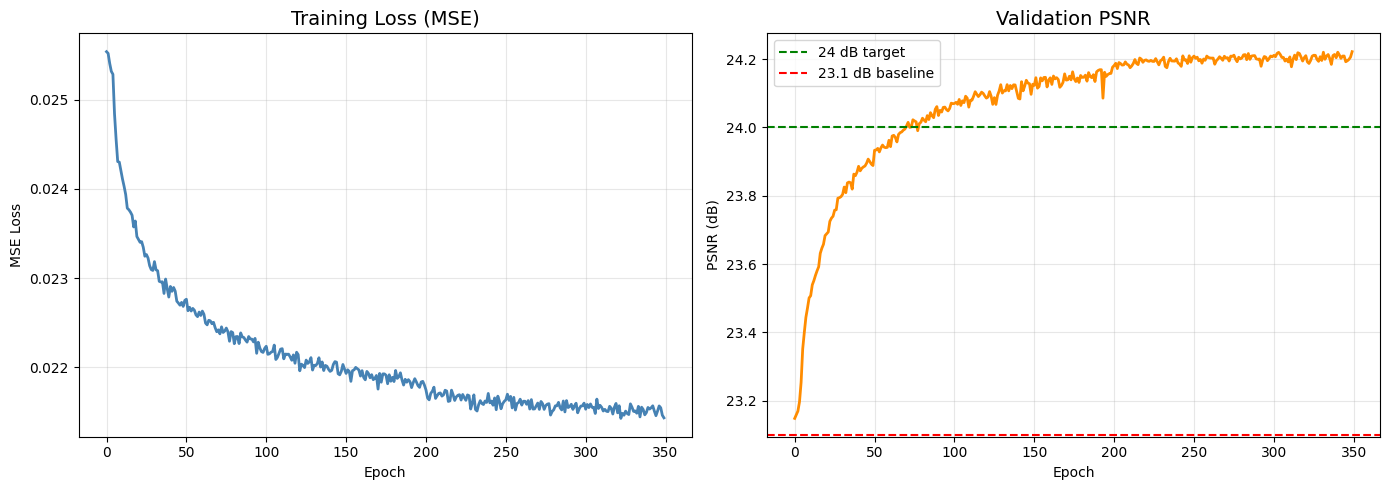

Saved to Drive!


In [21]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(train_losses, color='steelblue', linewidth=2)
ax1.set_title('Training Loss (MSE)', fontsize=14)
ax1.set_xlabel('Epoch')
ax1.set_ylabel('MSE Loss')
ax1.grid(True, alpha=0.3)

ax2.plot(val_psnrs, color='darkorange', linewidth=2)
ax2.axhline(y=24,   color='green', linestyle='--', label='24 dB target')
ax2.axhline(y=23.1, color='red',   linestyle='--', label='23.1 dB baseline')
ax2.set_title('Validation PSNR', fontsize=14)
ax2.set_xlabel('Epoch')
ax2.set_ylabel('PSNR (dB)')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'training_curves.png'), dpi=150)
plt.show()
print('Saved to Drive!')

## Cell 16: Visualize Predictions

Best model: Epoch 350 | PSNR: 24.22 dB


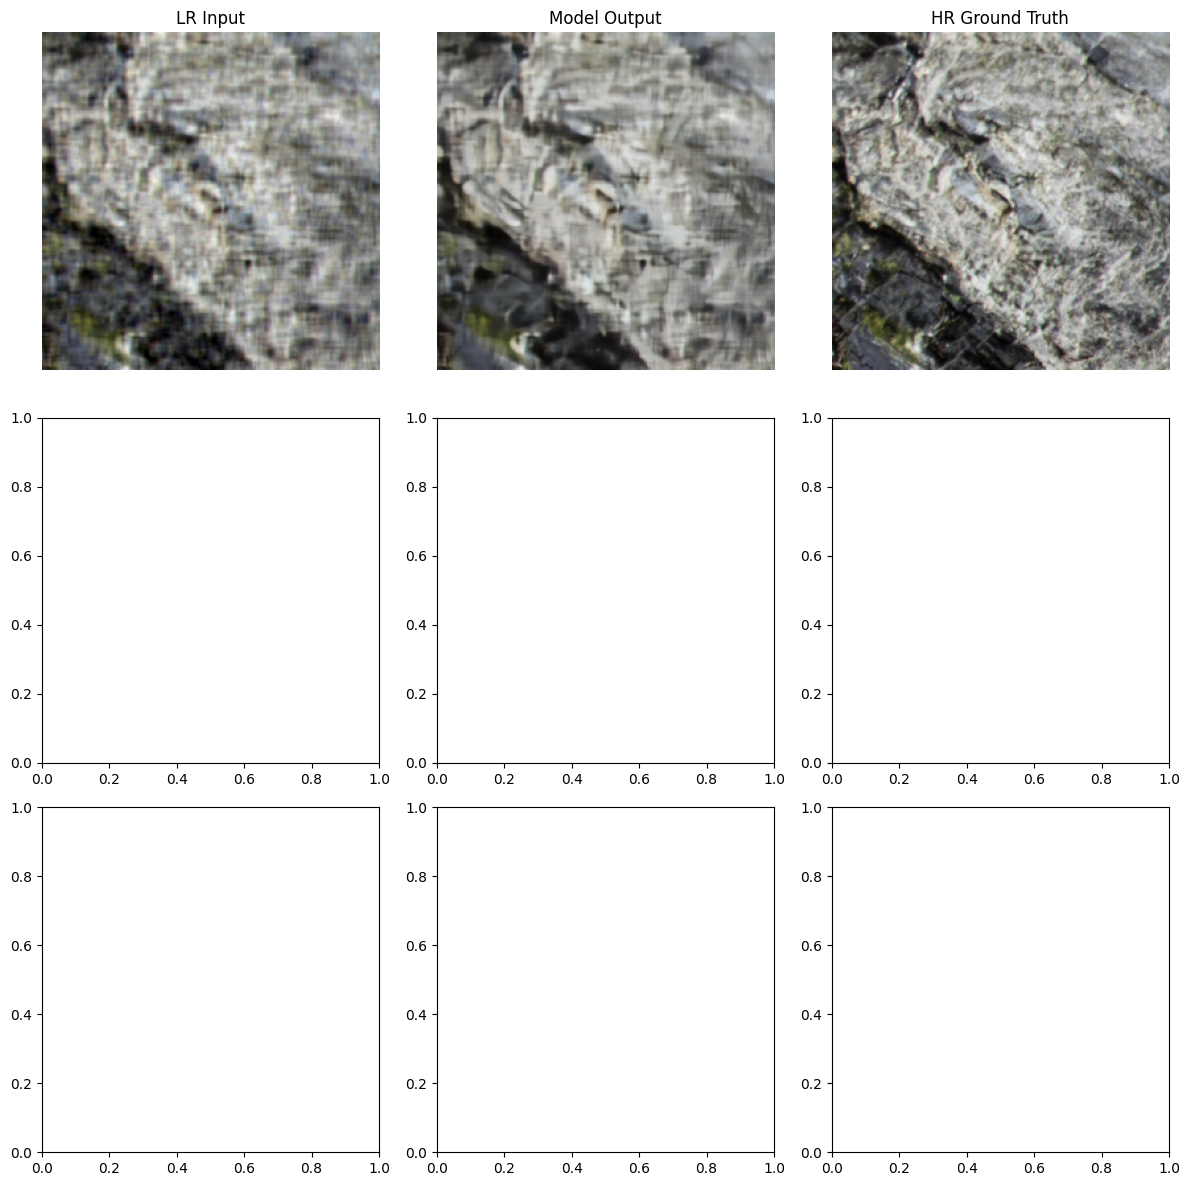

Predictions saved!


In [23]:
checkpoint = torch.load(
    os.path.join(SAVE_DIR, 'best_model.pth'),
    map_location=DEVICE
)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()
print(f'Best model: Epoch {checkpoint["epoch"]} | PSNR: {checkpoint["best_psnr"]:.2f} dB')

fig, axes = plt.subplots(3, 3, figsize=(12, 12))
axes[0,0].set_title('LR Input',        fontsize=12)
axes[0,1].set_title('Model Output',    fontsize=12)
axes[0,2].set_title('HR Ground Truth', fontsize=12)

lr_batch, hr_batch = next(iter(val_loader))
lr_batch = lr_batch.to(DEVICE)
hr_batch = hr_batch.to(DEVICE)

with torch.no_grad():
    pred_batch = model(lr_batch)

for i in range(min(3, lr_batch.shape[0])):
    lr_np   = lr_batch[i].cpu().permute(1,2,0).numpy().clip(0,1)
    pred_np = pred_batch[i].cpu().permute(1,2,0).numpy().clip(0,1)
    hr_np   = hr_batch[i].cpu().permute(1,2,0).numpy().clip(0,1)
    psnr_v  = compute_psnr(pred_batch[i], hr_batch[i])

    axes[i,0].imshow(lr_np);   axes[i,0].axis('off')
    axes[i,1].imshow(pred_np); axes[i,1].set_xlabel(f'PSNR: {psnr_v:.2f} dB'); axes[i,1].axis('off')
    axes[i,2].imshow(hr_np);   axes[i,2].axis('off')

plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'sample_predictions.png'), dpi=150)
plt.show()
print('Predictions saved!')

## Cell 17: Save Calibration Images

In [24]:
CALIB_DIR = os.path.join(SAVE_DIR, 'calibration_images')
os.makedirs(CALIB_DIR, exist_ok=True)

NUM_CALIB_PER_ZIP = 10
calib_count = 0

for lr_dir in lr_train_dirs:
    files = sorted([
        f for f in glob(os.path.join(lr_dir, '**', '*'), recursive=True)
        if f.lower().endswith(('.png', '.jpg', '.jpeg'))
    ])
    step     = max(1, len(files) // NUM_CALIB_PER_ZIP)
    selected = files[::step][:NUM_CALIB_PER_ZIP]

    for f in selected:
        img = Image.open(f).convert('RGB')
        img = img.resize((256, 256), Image.BILINEAR)
        img.save(os.path.join(CALIB_DIR, f'calib_{calib_count:03d}.jpg'))
        calib_count += 1

print(f'Saved {calib_count} calibration images ')
print(f'Location: {CALIB_DIR}')

Saved 50 calibration images 
Location: /content/drive/MyDrive/Lab3/outputs_swift2/calibration_images


## Cell 18: Export ONNX — Single File (opset 11)

In [25]:
import onnx

checkpoint = torch.load(
    os.path.join(SAVE_DIR, 'best_model.pth'),
    map_location='cpu'
)
model.load_state_dict(checkpoint['model_state_dict'])
model = model.cpu().eval()
print(f'Loaded: Epoch {checkpoint["epoch"]} | PSNR: {checkpoint["best_psnr"]:.2f} dB')

LOCAL_ONNX  = '/content/sr_model.onnx'
dummy_input = torch.randn(1, 3, 256, 256)

torch.onnx.export(
    model,
    dummy_input,
    LOCAL_ONNX,
    export_params=True,
    opset_version=11,
    do_constant_folding=True,
    input_names=['input'],
    output_names=['output'],
    dynamic_axes=None,
    verbose=False
)

# Merge into single file
onnx_model = onnx.load(LOCAL_ONNX)
onnx.save_model(onnx_model, LOCAL_ONNX, save_as_external_data=False)

# Verify
loaded = onnx.load(LOCAL_ONNX)
onnx.checker.check_model(loaded)
size_mb = os.path.getsize(LOCAL_ONNX) / 1e6
print(f'ONNX size  : {size_mb:.2f} MB')
print(f'Opset      : {loaded.opset_import[0].version}')
print(f'Single file: ')

DRIVE_ONNX = os.path.join(SAVE_DIR, 'sr_model.onnx')
shutil.copy2(LOCAL_ONNX, DRIVE_ONNX)
model = model.to(DEVICE)
print(f'Saved to Drive ')

Loaded: Epoch 350 | PSNR: 24.22 dB


W0426 08:14:48.049000 3836 torch/onnx/_internal/exporter/_compat.py:125] Setting ONNX exporter to use operator set version 18 because the requested opset_version 11 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features
W0426 08:14:49.026000 3836 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'input' from (input, rois, spatial_scale: 'float', pooled_height: 'int', pooled_width: 'int', sampling_ratio: 'int' = -1, aligned: 'bool' = False). Treating as an Input.
W0426 08:14:49.027000 3836 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'rois' from (input, rois, spatial_scale: 'float', pooled_height: 'int', pooled_width: 'int', sampling_ratio

ONNX size  : 7.80 MB
Opset      : 18
Single file: 
Saved to Drive 


## Cell 19: Final Summary

In [ ]:
total_params = sum(p.numel() for p in model.parameters())
onnx_size_mb = os.path.getsize(LOCAL_ONNX) / 1e6

print('=' * 65)
print('LAB 3 — COMPLETE!')
print('=' * 65)
print(f'Architecture         : SwiftSRNet (base_ch=26, blocks=7)')
print(f'Total Parameters     : {total_params:,}')
print(f'Best Validation PSNR : {best_psnr:.2f} dB')
print(f'Target 24 dB         : {" YES" if best_psnr > 24 else " NO"}')
print(f'ONNX file size       : {onnx_size_mb:.2f} MB')
print()
print('GRADING (latency is main metric!):')
print('  PSNR > 24 + Latency < 6ms  → 18 pts')
print('  PSNR > 24 + Latency < 8ms  → 17 pts')
print('  PSNR > 24 + Latency < 10ms → 16 pts')
print('  PSNR <= 24                 → 8 pts')
print()
print('CANVAS SUBMISSION:')
print('   training notebook (.ipynb)')
print('   onnx_to_mxq.py')
print('   sr_model.mxq')
print('   best_model.pth')
print('=' * 65)